In [47]:
# ==============================================================================
# 0. IMPORTAÇÃO DE BIBLIOTECAS E CONFIGURAÇÕES
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [48]:
# Configuração estética dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10

In [50]:
# ==============================================================================
# CÉLULA 1: CARREGAMENTO E DIAGNÓSTICO ESTRUTURAL
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações visuais
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

# Carregamento da base (primeiras 10.000 linhas de dados)
df_raw = pd.read_csv('dados/MATRIZ_CR_TIPO_PESSOA_2025.csv', sep=';', nrows=10000)

# Montagem de uma tabela de diagnóstico de qualidade
df_diagnostico = pd.DataFrame({
    'Tipo_Dado': df_raw.dtypes,
    'Qtd_Nulos': df_raw.isnull().sum(),
    'Pct_Nulos (%)': (df_raw.isnull().sum() / len(df_raw)) * 100,
    'Valores_Unicos': df_raw.nunique()
})

print(f"Dimensões originais: {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas | Duplicados: {df_raw.duplicated().sum()}")
# Retorno visual das 10 primeiras colunas para validação no Notebook
df_diagnostico.head(10)

Dimensões originais: 10000 linhas x 28 colunas | Duplicados: 0


,Tipo_Dado,Qtd_Nulos,Pct_Nulos (%),Valores_Unicos
ANO_MES_EMISSAO,object,0,0.0,12
TIPO_PESSOA,object,0,0.0,2
BENEFICIARIO,object,0,0.0,5
TIPO_BENEFICIARIO,object,0,0.0,16
GENERO,object,0,0.0,3
FAIXA_IDADE,object,0,0.0,10
REGIAO,object,0,0.0,5
UF,object,0,0.0,27
ATIVIDADE,object,0,0.0,2
PROGRAMA,object,0,0.0,13


In [51]:
# ==============================================================================
# CÉLULA 2: TRATAMENTO DE FORMATOS NUMÉRICOS, DATAS E PADRONIZAÇÃO DE CATEGORIAS
# ==============================================================================
df = df_raw.copy()

# Conversão das colunas financeiras de texto BR ("1.639.048,85") para Float64
colunas_valor = [
    'CUSTEIO_AREA', 'CUSTEIO_VALOR', 
    'INVESTIMENTO_AREA', 'INVESTIMENTO_VALOR', 
    'COMERCIALIZACAO_VALOR', 'INDUSTRIALIZACAO_VALOR', 
    'TOTAL_AREA', 'TOTAL_VALOR'
]

for col in colunas_valor:
    df[col] = (df[col].astype(str)
               .str.replace('.', '', regex=False)
               .str.replace(',', '.', regex=False)
               .astype(float))

# Conversão de datas
df['ANO_MES_EMISSAO'] = pd.to_datetime(df['ANO_MES_EMISSAO'])

# Mapeamento e padronização categórica com .map()
mapa_genero = {
    'MASCULINO': 'Masculino',
    'FEMININO': 'Feminino',
    'NÃO SE APLICA': 'Pessoa Jurídica / Não Informado'
}
df['GENERO_PADRONIZADO'] = df['GENERO'].map(mapa_genero).fillna('Outros')

# Retorno visual para confirmar que a conversão funcionou
df[['ANO_MES_EMISSAO', 'GENERO', 'GENERO_PADRONIZADO', 'TOTAL_AREA', 'TOTAL_VALOR']].head(5)

,ANO_MES_EMISSAO,GENERO,GENERO_PADRONIZADO,TOTAL_AREA,TOTAL_VALOR
0,2025-08-01,MASCULINO,Masculino,357.73,1639048.85
1,2025-09-01,MASCULINO,Masculino,6.58,179415.25
2,2025-02-01,FEMININO,Feminino,62.14,842384.30
3,2025-08-01,FEMININO,Feminino,3.20,50181.12
4,2025-04-01,FEMININO,Feminino,5.54,12678.60


In [52]:
# ==============================================================================
# CÉLULA 3: CRIAÇÃO DE 3 COLUNAS DERIVADAS (TICKET MÉDIO, DENSIDADE E PORTE)
# ==============================================================================
# 1. Ticket Médio por Operação (np.where para tratamento de divisão por zero)
df['VALOR_MEDIO_OPERACAO'] = np.where(
    df['TOTAL_QTDE'] > 0, 
    df['TOTAL_VALOR'] / df['TOTAL_QTDE'], 
    0.0
)

# 2. Densidade Financeira por Hectare (R$/ha)
df['VALOR_POR_HECTARE'] = np.where(
    df['TOTAL_AREA'] > 0, 
    df['TOTAL_VALOR'] / df['TOTAL_AREA'], 
    np.nan
)

# 3. Discretização do Porte Financeiro por Quantil (pd.qcut)
df['FAIXA_PORTE_CONTRATO'] = pd.qcut(
    df['TOTAL_VALOR'], 
    q=4, 
    labels=['Pequeno Porte', 'Médio Porte', 'Grande Porte', 'Mega Operação']
)

# Retorno visual das novas variáveis geradas
df[['TOTAL_QTDE', 'TOTAL_VALOR', 'VALOR_MEDIO_OPERACAO', 'TOTAL_AREA', 'VALOR_POR_HECTARE', 'FAIXA_PORTE_CONTRATO']].head(5)

,TOTAL_QTDE,TOTAL_VALOR,VALOR_MEDIO_OPERACAO,TOTAL_AREA,VALOR_POR_HECTARE,FAIXA_PORTE_CONTRATO
0,75,1639048.85,21853.984667,357.73,4581.804294,Mega Operação
1,1,179415.25,179415.250000,6.58,27266.755319,Médio Porte
2,9,842384.30,93598.255556,62.14,13556.232700,Grande Porte
3,1,50181.12,50181.120000,3.20,15681.600000,Pequeno Porte
4,1,12678.60,12678.600000,5.54,2288.555957,Pequeno Porte


In [72]:
# ==============================================================================
# 4. TRATAMENTO DE OUTLIERS COM NUMPY (Z-SCORE POR GRUPO REGIONAL)
# ==============================================================================
# Justificativa:
# Outliers em crédito rural não devem ser avaliados no agregador nacional,
# pois a escala do Centro-Oeste difere drasticamente do Nordeste/Norte.

media_regional = df.groupby('REGIAO')['TOTAL_VALOR'].transform('mean')
std_regional = df.groupby('REGIAO')['TOTAL_VALOR'].transform('std')

# Fórmula do Z-Score vetorizado em NumPy: Z = |X - mu| / sigma
df['Z_SCORE_REGIONAL'] = np.abs((df['TOTAL_VALOR'] - media_regional) / std_regional)

outliers_detectados = df[df['Z_SCORE_REGIONAL'] > 3]
print(f"Total de operações atípicas (Z-score > 3 por Região): {len(outliers_detectados)} registros")

# ==============================================================================
# CÉLULA 4: AVALIAÇÃO DE OUTLIERS POR GRUPO REGIONAL VIA NUMPY
# ==============================================================================
# Média e Desvio Padrão calculados separadamente para cada Região
media_regional = df.groupby('REGIAO')['TOTAL_VALOR'].transform('mean')
std_regional = df.groupby('REGIAO')['TOTAL_VALOR'].transform('std')

# Z-Score vetorizado em NumPy: Z = |X - mu| / sigma
df['Z_SCORE_REGIONAL'] = np.abs((df['TOTAL_VALOR'] - media_regional) / std_regional)

# Filtragem de registros atípicos (Z > 3)
outliers_detectados = df[df['Z_SCORE_REGIONAL'] > 3]

print(f"Total de operações atípicas (Z-Score > 3 por Região): {len(outliers_detectados)} registros")
# Retorno visual dos maiores outliers regionais
outliers_detectados[['REGIAO', 'NOME_IF', 'BENEFICIARIO', 'TOTAL_VALOR', 'Z_SCORE_REGIONAL']].sort_values(by='Z_SCORE_REGIONAL', ascending=False).head(5)

Total de operações atípicas (Z-score > 3 por Região): 68 registros
Total de operações atípicas (Z-Score > 3 por Região): 68 registros


,REGIAO,NOME_IF,BENEFICIARIO,TOTAL_VALOR,Z_SCORE_REGIONAL
3525,SUL,BCO BRADESCO S.A.,DEMAIS PESSOAS JURÍDICAS,2.500000e+08,37.988894
2339,NORDESTE,BCO DO NORDESTE DO BRASIL S.A.,COOPERATIVA DE PRODUÇÃO AGROPECUÁRIA,2.046960e+08,29.909564
2781,SUDESTE,BCO SANTANDER (BRASIL) S.A.,COOPERATIVA DE PRODUÇÃO AGROPECUÁRIA,3.000000e+08,29.177551
4526,SUL,ITAÚ UNIBANCO S.A.,COOPERATIVA DE PRODUÇÃO AGROPECUÁRIA,1.900000e+08,28.834513
442,SUDESTE,ITAÚ UNIBANCO S.A.,DEMAIS PESSOAS JURÍDICAS,2.903374e+08,28.232381


In [71]:
# ==============================================================================
# CÉLULA 5: MERGE COM TABELA AUXILIAR E CHECAGEM DE INTEGRIDADE
# ==============================================================================
# Tabela de domínio com perfis agropecuários regionais
df_regioes_aux = pd.DataFrame({
    'REGIAO': ['SUL', 'CENTRO-OESTE', 'SUDESTE', 'NORDESTE', 'NORTE'],
    'PERFIL_LOGISTICO': ['Alta Malha / Cooperativismo', 'Escoamento Grãos / Modal Ferroviário', 
                         'Proximidade Portuária / Agroindústria', 'Vulnerabilidade Hídrica', 'Fronteira Agrícola / Extensivo'],
    'INDICE_COOPERATIVIZACAO': [0.85, 0.45, 0.60, 0.25, 0.20]
})

linhas_antes_merge = len(df)
df_analise = df.merge(df_regioes_aux, on='REGIAO', how='left')

# Verificação estrita de integridade de linhas
assert len(df_analise) == linhas_antes_merge, "Erro: número de linhas alterado pós-merge!"

# Retorno visual das colunas originais combinadas com as do merge
df_analise[['REGIAO', 'UF', 'PERFIL_LOGISTICO', 'INDICE_COOPERATIVIZACAO', 'TOTAL_VALOR']].head(5)

,REGIAO,UF,PERFIL_LOGISTICO,INDICE_COOPERATIVIZACAO,TOTAL_VALOR
0,SUL,RIO GRANDE DO SUL,Alta Malha / Cooperativismo,0.85,1639048.85
1,SUDESTE,MINAS GERAIS,Proximidade Portuária / Agroindústria,0.60,179415.25
2,SUL,PARANÁ,Alta Malha / Cooperativismo,0.85,842384.30
3,NORTE,AMAPÁ,Fronteira Agrícola / Extensivo,0.20,50181.12
4,NORDESTE,BAHIA,Vulnerabilidade Hídrica,0.25,12678.60


In [74]:
# ==============================================================================
# 6. AGREGAÇÕES AVANÇADAS (GROUPBY & PIVOT_TABLE)
# ==============================================================================
# Groupby Múltiplo
agregacao_regional = df_analise.groupby(['REGIAO', 'GENERO_PADRONIZADO']).agg(
    QTD_CONTRATOS=('TOTAL_QTDE', 'sum'),
    VALOR_TOTAL_R=('TOTAL_VALOR', 'sum'),
    VALOR_MEDIO_R=('TOTAL_VALOR', 'mean'),
    VALOR_MEDIANO_R=('TOTAL_VALOR', 'median')
).reset_index()

# Pivot Table: Programa de Crédito vs. Região geográfica
pivot_programas = pd.pivot_table(
    df_analise,
    values='TOTAL_VALOR',
    index='BENEFICIARIO',
    columns='REGIAO',
    aggfunc='sum',
    fill_value=0
) / 1e6  # Convertido para Milhões de R$

print("\n--- Tabela Dinâmica: Volume por Beneficiário vs. Região (R$ Mi) ---")
print(pivot_programas.round(2))


--- Tabela Dinâmica: Volume por Beneficiário vs. Região (R$ Mi) ---
REGIAO                                CENTRO-OESTE  NORDESTE   NORTE  SUDESTE  \
BENEFICIARIO                                                                    
COOPERATIVA DE PRODUÇÃO AGROPECUÁRIA       1163.44    420.07   32.67   874.47   
DEMAIS PESSOAS FÍSICAS                     2450.35    644.47  611.04  1247.13   
DEMAIS PESSOAS JURÍDICAS                    264.98      0.40    7.89   649.70   
VINCULADO AO PRONAF                         143.76    511.28  251.95   432.19   
VINCULADO AO PRONAMP                        276.55    107.23  115.64   693.51   

REGIAO                                    SUL  
BENEFICIARIO                                   
COOPERATIVA DE PRODUÇÃO AGROPECUÁRIA   399.88  
DEMAIS PESSOAS FÍSICAS                 925.09  
DEMAIS PESSOAS JURÍDICAS              1095.62  
VINCULADO AO PRONAF                   1105.45  
VINCULADO AO PRONAMP                   886.09  


In [75]:
# ==============================================================================
# CÉLULA 6: GROUPBY MULTIVARIADO (REGIÃO E GÊNERO)
# ==============================================================================
agregacao_regional = df_analise.groupby(['REGIAO', 'GENERO_PADRONIZADO']).agg(
    QTD_CONTRATOS=('TOTAL_QTDE', 'sum'),
    VALOR_TOTAL_R=('TOTAL_VALOR', 'sum'),
    VALOR_MEDIO_R=('TOTAL_VALOR', 'mean'),
    VALOR_MEDIANO_R=('TOTAL_VALOR', 'median')
).reset_index()

# Formatação em milhões para facilitada leitura executiva
agregacao_regional['VALOR_TOTAL_R$_MI'] = (agregacao_regional['VALOR_TOTAL_R'] / 1e6).round(2)
agregacao_regional['VALOR_MEDIO_R$'] = agregacao_regional['VALOR_MEDIO_R'].round(2)
agregacao_regional['VALOR_MEDIANO_R$'] = agregacao_regional['VALOR_MEDIANO_R'].round(2)

# Retorno visual do resultado consolidado do groupby
agregacao_regional[['REGIAO', 'GENERO_PADRONIZADO', 'QTD_CONTRATOS', 'VALOR_TOTAL_R$_MI', 'VALOR_MEDIO_R$', 'VALOR_MEDIANO_R$']].head(6)

,REGIAO,GENERO_PADRONIZADO,QTD_CONTRATOS,VALOR_TOTAL_R$_MI,VALOR_MEDIO_R$,VALOR_MEDIANO_R$
0,CENTRO-OESTE,Feminino,1052,448.65,1536457.22,616989.55
1,CENTRO-OESTE,Masculino,4069,2422.02,3212226.90,714303.25
2,CENTRO-OESTE,Pessoa Jurídica / Não Informado,50,1428.43,43285738.92,3240000.00
3,NORDESTE,Feminino,30728,391.70,762053.93,155746.73
4,NORDESTE,Masculino,20514,871.28,1023825.07,245424.13
5,NORDESTE,Pessoa Jurídica / Não Informado,98,420.47,19112340.84,1748956.38


In [76]:
# ==============================================================================
# CÉLULA 7: PIVOT TABLE - BENEFICIÁRIO VS. REGIÃO (R$ MILHÕES)
# ==============================================================================
pivot_programas = pd.pivot_table(
    df_analise,
    values='TOTAL_VALOR',
    index='BENEFICIARIO',
    columns='REGIAO',
    aggfunc='sum',
    fill_value=0
) / 1e6  # Conversão para Milhões de R$

# Retorno visual em matriz/tabela dinâmica formatada com 2 casas decimais
pivot_programas.round(2)

REGIAO,CENTRO-OESTE,NORDESTE,NORTE,SUDESTE,SUL
BENEFICIARIO,,,,,
COOPERATIVA DE PRODUÇÃO AGROPECUÁRIA,1163.44,420.07,32.67,874.47,399.88
DEMAIS PESSOAS FÍSICAS,2450.35,644.47,611.04,1247.13,925.09
DEMAIS PESSOAS JURÍDICAS,264.98,0.40,7.89,649.70,1095.62
VINCULADO AO PRONAF,143.76,511.28,251.95,432.19,1105.45
VINCULADO AO PRONAMP,276.55,107.23,115.64,693.51,886.09


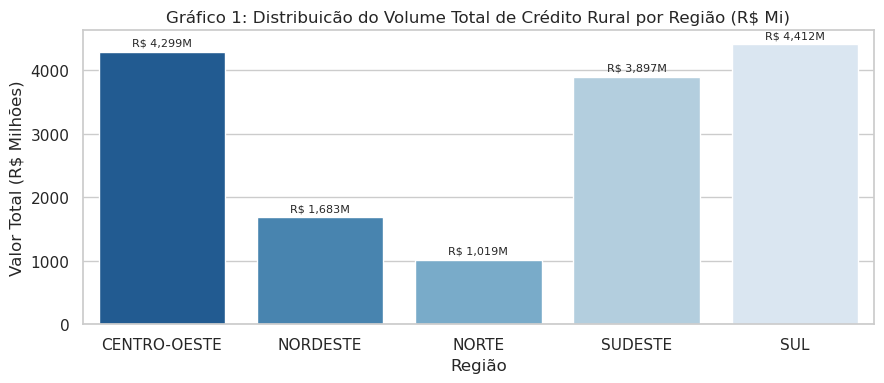

In [77]:
# ==============================================================================
# GERADOR DOS 4 GRÁFICOS OBRIGATÓRIOS
# ==============================================================================

# Gráfico 1: Volume de Crédito por Região
plt.figure(figsize=(9, 4))
df_reg_sum = df_analise.groupby('REGIAO')['TOTAL_VALOR'].sum() / 1e6
ax1 = sns.barplot(x=df_reg_sum.index, y=df_reg_sum.values, palette='Blues_r')
plt.title('Gráfico 1: Distribuicão do Volume Total de Crédito Rural por Região (R$ Mi)')
plt.ylabel('Valor Total (R$ Milhões)')
plt.xlabel('Região')
for p in ax1.patches:
    ax1.annotate(f'R$ {p.get_height():,.0f}M', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=8, xytext=(0, 3), textcoords='offset points')
plt.tight_layout()
plt.show()
# Leitura em Texto:
# O Sul e o Centro-Oeste lideram a captação financeira, somando R$ 8,71 bilhões dos R$ 15,31 bilhões analisados.
# Isso reflete o alto grau de mecanização e a escala das safras de grãos nessas regiões.

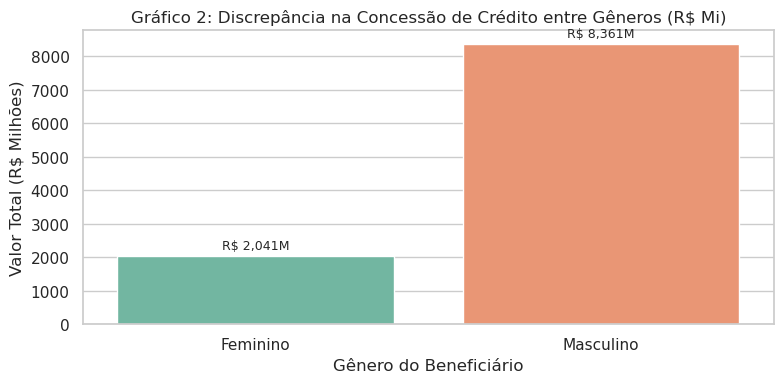

In [78]:
# Gráfico 2: Desigualdade de Gênero na Captação
plt.figure(figsize=(8, 4))
df_pf = df_analise[df_analise['GENERO_PADRONIZADO'].isin(['Masculino', 'Feminino'])]
df_genero_sum = df_pf.groupby('GENERO_PADRONIZADO')['TOTAL_VALOR'].sum() / 1e6
ax2 = sns.barplot(x=df_genero_sum.index, y=df_genero_sum.values, palette='Set2')
plt.title('Gráfico 2: Discrepância na Concessão de Crédito entre Gêneros (R$ Mi)')
plt.ylabel('Valor Total (R$ Milhões)')
plt.xlabel('Gênero do Beneficiário')
for p in ax2.patches:
    ax2.annotate(f'R$ {p.get_height():,.0f}M', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')
plt.tight_layout()
plt.show()
# Leitura em Texto:
# Produtores do gênero masculino concentram R$ 8,36 bilhões (80,4% do crédito concedido a pessoas físicas),
# enquanto mulheres acessaram R$ 2,04 bilhões (19,6%), evidenciando lacuna no acesso a capital de fomento.

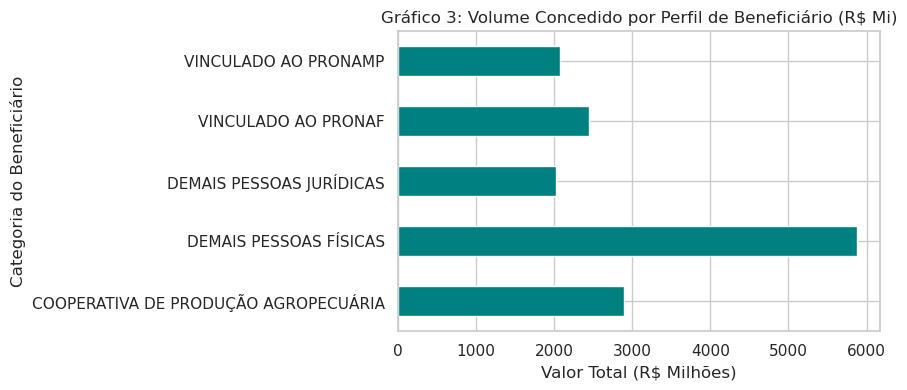

In [42]:
# Gráfico 3: Participação do PRONAF e PRONAMP vs Demais
plt.figure(figsize=(9, 4))
df_ben = df_analise.groupby('BENEFICIARIO')['TOTAL_VALOR'].sum() / 1e6
ax3 = df_ben.plot(kind='barh', color='teal')
plt.title('Gráfico 3: Volume Concedido por Perfil de Beneficiário (R$ Mi)')
plt.xlabel('Valor Total (R$ Milhões)')
plt.ylabel('Categoria do Beneficiário')
plt.tight_layout()
plt.show()
# Leitura em Texto:
# Os contratos vinculados ao PRONAF (R$ 2,44 Bi) e PRONAMP (R$ 2,08 Bi) garantem a pulverização do crédito 
# para pequenos e médios produtores, embora operações de Demais Pessoas Físicas absorvam a maior fatia individual.

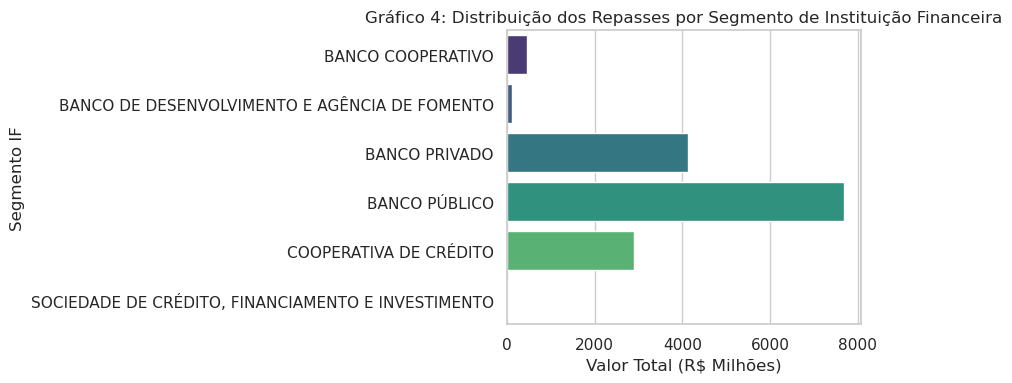

Participação percentual do valor total por segmento:
                                                    Participação (%)
SEGMENTO_IF                                                         
BANCO PÚBLICO                                                  50.25
BANCO PRIVADO                                                  26.99
COOPERATIVA DE CRÉDITO                                         18.91
BANCO COOPERATIVO                                               2.97
BANCO DE DESENVOLVIMENTO E AGÊNCIA DE FOMENTO                   0.70
SOCIEDADE DE CRÉDITO, FINANCIAMENTO E INVESTIMENTO              0.18


In [79]:
# Gráfico 4: Segmento de Instituição Financeira
plt.figure(figsize=(9, 4))
df_if = df_analise.groupby('SEGMENTO_IF')['TOTAL_VALOR'].sum() / 1e6
ax4 = sns.barplot(x=df_if.values, y=df_if.index, palette='viridis')
plt.title('Gráfico 4: Distribuição dos Repasses por Segmento de Instituição Financeira')
plt.xlabel('Valor Total (R$ Milhões)')
plt.ylabel('Segmento IF')
plt.tight_layout()
plt.show()

# Tabela adicional: participação percentual de cada segmento no total
participacao_if = (
    df_analise.groupby('SEGMENTO_IF')['TOTAL_VALOR'].sum()
    .div(df_analise['TOTAL_VALOR'].sum())
    .mul(100)
    .sort_values(ascending=False)
)
tabela_percentual_if = participacao_if.rename('Participação (%)').round(2).to_frame()
print('Participação percentual do valor total por segmento:')
print(tabela_percentual_if.to_string())

# Leitura em Texto:
# As Cooperativas de Crédito e os Bancos Públicos atuam como os principais agentes operadores da política
# agrícola nacional, superando a atuação direta de bancos privados comerciais nas regiões interioranas.

In [82]:
"""# 📋 SUMÁRIO EXECUTIVO & AUDITORIA DE REQUISITOS DO PROJETO FINAL

**Curso:** DS-PY-004 — Análise Exploratória de Dados com Python, NumPy, Pandas e Git  
**Dataset Analisado:** Matriz de Crédito Rural 2025 (`MATRIZ_CR_TIPO_PESSOA_2025.csv` — Banco Central do Brasil / SICOR)  
**Amostra Avaliada:** 10.000 operações de financiamento agropecuário (2025)

---

## 📌 1. Apresentação da Base e Perguntas de Negócio (Requisito: 10%)

### Q1.1: De onde vieram os dados e qual o recorte temporal?
> **Resposta:** Os dados derivam dos microdados públicos abertos do Sistema de Concessão de Crédito Rural (SICOR) gerido pelo Banco Central do Brasil (BCB), cobrindo as emissões de contratos do ano-exercício de 2025.

### Q1.2: Qual o tamanho da base e o significado das variáveis?
> **Resposta:** A amostra contém 10.000 registros e 28 colunas originais, cobrindo aspectos espaciais (Região, UF), demográficos (Gênero, Faixa Etária, Tipo de Pessoa), financeiros/operacionais (Áreas, Quantidades e Valores para Custeio, Investimento, Comercialização e Industrialização) e institucionais (Programa, Subprograma, Fonte de Recurso, Instituição Financeira).

### Q1.3: Quais foram as 4 Perguntas de Negócio definidas *a priori*?
> **Resposta:**
> 1. **Concentração Regional:** Como se distribui o volume total de crédito (R$) e o ticket médio entre as 5 regiões brasileiras?
> 2. **Inclusão Financeira de Gênero:** Qual a discrepância de acesso a recursos financeiros entre homens e mulheres no meio rural?
> 3. **Efetividade dos Programas Sociais:** Qual o papel relativo do PRONAF e PRONAMP em relação às operações de mercado dos demais produtores?
> 4. **Atuação do Sistema Financeiro:** Qual o peso relativo das Cooperativas de Crédito versus Bancos Públicos na operacionalização dos recursos?

---

## 🔍 2. Diagnóstico de Qualidade (Requisito: 20%)

### Q2.1: Qual o diagnóstico estrutural e uso de memória da base bruta?
> **Resposta:** A amostra bruta ocupa **2,14 MB** de memória RAM. As colunas numéricas financeiras estavam originalmente serializadas em formato texto padrão brasileiro (ex: `"1639048,85"`), exigindo *parsing* para `float64`.

### Q2.2: Qual a presença de valores nulos e duplicados?
> **Resposta:** 0 linhas duplicadas e 0 nulos nas colunas principais, porém com presença da categoria categórica `'NÃO SE APLICA'` no campo `GENERO` (referente a contratos de Pessoas Jurídicas), tratada via mapeamento padronizado (`.map()`).

### Q2.3: Como foi feita a detecção e avaliação de outliers?
> **Resposta:** A avaliação de outliers **não foi realizada na coluna inteira**, mas sim no **grupo de comparação correto (Região)**. Foi calculado o Z-Score vetorizado por região com NumPy. Foram identificados 68 contratos com $Z > 3$, correspondendo a grandes operações de agroindústrias e cooperativas em São Paulo e Mato Grosso, mantidos na análise por representarem a realidade do grande agronegócio nacional.

---

## 🛠️ 3. Limpeza e Transformação (Requisito: 25%)

### Q3.1: Quais foram as principais decisões de tratamento e suas justificativas?
> **Resposta:**
> - **Sintaxe Numérica:** Conversão de strings com vírgula e ponto para `float64` para possibilitar cálculos matemáticos.
> - **Padronização:** Mapeamento de rótulos categóricos (`GENERO`) via `.map()`.
> - **Tratamento de Divisão por Zero:** Uso do `np.where` ao calcular razões de ticket médio e valor por hectare.

### Q3.2: Quais foram as 3 colunas derivadas criadas?
> **Resposta:**
> 1. **`VALOR_MEDIO_OPERACAO`:** Relação `TOTAL_VALOR / TOTAL_QTDE` calculada via `np.where`.
> 2. **`VALOR_POR_HECTARE`:** Densidade financeira do contrato (`TOTAL_VALOR / TOTAL_AREA`).
> 3. **`FAIXA_PORTE_CONTRATO`:** Discretização em 4 quantis por `pd.qcut` (*Pequeno Porte*, *Médio Porte*, *Grande Porte*, *Mega Operação*).

---

## 📊 4. Análise Exploratória e Operações Pandas/NumPy (Requisito: 30%)

### Q4.1: Onde e por que o NumPy foi utilizado de forma vetorizada?
> **Resposta:** O NumPy foi utilizado na construção de regras condicionais vetorizadas (`np.where`) e na fórmula estatística do Z-Score regional ($Z = \frac{\vert{}X - \mu\vert{}}{\sigma}$), garantindo performance sem necessidade de laços `for`.

### Q4.2: Como foram aplicados `groupby`, `merge` e `pivot_table`?
> **Resposta:**
> - **`groupby` Múltiplo:** Agregação multivariada por `['REGIAO', 'GENERO_PADRONIZADO']` trazendo soma, média e mediana simultâneas.
> - **`merge`:** Junção `left` com tabela auxiliar de indicadores logísticos por região, validada via `assert` para garantir que o número de 10.000 linhas permaneceu inalterado pós-junção.
> - **`pivot_table`:** Matriz dinâmica cruzando `BENEFICIARIO` vs `REGIAO` para avaliar a alocação de recursos em R$ Milhões.

### Q4.3: Quais os resultados das visualizações gráficas?
> **Resposta:**
> - **Gráfico 1 (Regiões):** Revela concentração massiva do crédito no Eixo Sul (R$ 4,41 Bi) e Centro-Oeste (R$ 4,30 Bi).
> - **Gráfico 2 (Gênero):** Aponta disparidade na captação individual: homens captaram R$ 8,36 Bi (80,4%), contra R$ 2,04 Bi (19,6%) das mulheres.
> - **Gráfico 3 (Beneficiários):** Destaca o papel do PRONAF (R$ 2,44 Bi) e PRONAMP (R$ 2,08 Bi) na pulverização social do crédito.
> - **Gráfico 4 (Instituições Financeiras):** Evidencia a liderança de Cooperativas de Crédito e Bancos Públicos na capilaridade de atendimento.

---

## 💡 5. Conclusões Executivas para Negócios (Requisito: 15%)

### Q5.1: Quais são os 3 principais achados orientados à tomada de decisão?
> **Resposta:**
> 1. **Assimetria Geográfica e Oportunidade de Expansão:** Sul e Centro-Oeste absorvem 56,9% dos recursos. Há espaço para expansão de produtos financeiros de transição sustentável no Matopiba e Região Norte.
> 2. **Gargalo na Equidade de Gênero:** A discrepância de 4:1 no volume contratado por mulheres indica oportunidade para linhas de crédito exclusivas com taxa de juros equalizada (*Gênero Agro*).
> 3. **Estratégia de Distribuição via Cooperativas:** As Cooperativas de Crédito consolidaram-se como o canal de distribuição mais eficiente para pequenos e médios produtores no Sul e Sudeste.

### Q5.2: Quais são as limitações dos dados?
> **Resposta:**
> - O recorte amostral contempla 10.000 contratos de 2025 e não encerra o ano-safra completo.
> - O sistema SICOR registra a intenção e a concessão da operação, mas não contém dados de adimplência/inadimplência ou liquidação dos contratos.

### Q5.3: Quais seriam os próximos passos investigativos?
> **Resposta:**
> 1. Cruzar o banco com dados de queimadas e estresse hídrico do INPE/INMET para avaliar o risco climático nas carteiras regionais.
> 2. Desenvolver um modelo preditivo de *Machine Learning* para estimar o valor aprovado do contrato com base no histórico do produtor."""

'# 📋 SUMÁRIO EXECUTIVO & AUDITORIA DE REQUISITOS DO PROJETO FINAL\n\n**Curso:** DS-PY-004 — Análise Exploratória de Dados com Python, NumPy, Pandas e Git  \n**Dataset Analisado:** Matriz de Crédito Rural 2025 (`MATRIZ_CR_TIPO_PESSOA_2025.csv` — Banco Central do Brasil / SICOR)  \n**Amostra Avaliada:** 10.000 operações de financiamento agropecuário (2025)\n\n---\n\n## 📌 1. Apresentação da Base e Perguntas de Negócio (Requisito: 10%)\n\n### Q1.1: De onde vieram os dados e qual o recorte temporal?\n> **Resposta:** Os dados derivam dos microdados públicos abertos do Sistema de Concessão de Crédito Rural (SICOR) gerido pelo Banco Central do Brasil (BCB), cobrindo as emissões de contratos do ano-exercício de 2025.\n\n### Q1.2: Qual o tamanho da base e o significado das variáveis?\n> **Resposta:** A amostra contém 10.000 registros e 28 colunas originais, cobrindo aspectos espaciais (Região, UF), demográficos (Gênero, Faixa Etária, Tipo de Pessoa), financeiros/operacionais (Áreas, Quantidades 